> **中文阅读版**：本文件是 `05_10k_rag_assistant.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 10-K 尽职调查助手：带可验证引用的 RAG

**Docker 镜像**：`ml4t-gpu`

**第 22 章：面向金融研究的 RAG**

一个面向 10-K 申报文件的尽职调查助手：句子窗口分块（sentence-window chunking）、本地 BGE-small 嵌入、ChromaDB 索引，以及在一个要求引用与弃答的提示词下运行的查询引擎。

**随附运行会执行什么、不会执行什么。** `RUN_LIVE_LLM` 默认是 false，因此没有生成：查询引擎只是一个检索器，引用提示词只是写下来，从未发送。下文关于检索的一切都是实际测量的。关于引用与弃答的一切，都是 notebook 声明的契约，而不是它观察到的行为。打开该标志需要 OpenAI 密钥，并会使运行不可复现，这就是它默认关闭的原因。

被测量的检索会收到一个语料库能够回答的问题、三个无法回答的问题，以及一个关于氦沸点的问题。第 6 节讨论检索器如何报告这种差异。

**学习目标**

完成本 notebook 后，你将能够：

- 端到端构建申报文件索引：加载、分块、嵌入、持久化、检索。
- 说明为什么 `similarity_top_k` 检索器的命中数无法检测糟糕的检索，以及应当改测什么。
- 说明向量存储返回的分数实际上是什么，以及从排序到接受或弃答决策之间还隔着什么。
- 运行 retrieve-extract-compute-narrate 模式，并说明语言模型被排除在哪一步之外以及原因。

**前置条件**

- SP100 10-K 语料库。注意 [`01_sec_filing_pipeline`](01_sec_filing_pipeline.ipynb) 对其确立了什么：存储的文本是每份申报文件首次提及供应商处附近的一个窗口，而不是整份报告。第 5 节开始体现这一点的重要性。
- 用于嵌入的 CUDA GPU。无需 API 密钥：嵌入模型是本地模型，LLM 路径处于关闭状态。

**本书参考**：关于 10-K 助手的第 22.8 节，以及关于约束提示的第 22.6 节。

## 1. 设置

In [1]:
"""10-K Due Diligence Assistant - RAG pipeline with verifiable citations for SEC filings."""

import os
import re
from dataclasses import dataclass
from pathlib import Path

import chromadb
import plotly.graph_objects as go
import torch

# LlamaIndex core + ChromaDB + OpenAI LLM backend
from llama_index.core import (
    Document,
    PromptTemplate,
    Settings,
    SimpleDirectoryReader,
    StorageContext,
    VectorStoreIndex,
)
from llama_index.core.node_parser import SentenceSplitter
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openai import OpenAI as OpenAILLM
from llama_index.vector_stores.chroma import ChromaVectorStore

# ML4T configuration
from data import DataNotFoundError, iter_sec_filings
from utils.paths import get_output_dir
from utils.style import COLORS, show_plotly_with_alt

VECTOR_STORE_DIR = get_output_dir(22, "10k_rag_assistant") / "vector_store"
VECTOR_STORE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
MAX_DOCS = 20
TOP_K = 5
RUN_LIVE_LLM = False
REQUIRE_GPU = True

In [3]:
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError("This embedding workload requires the ml4t-gpu service with CUDA.")

EMBEDDING_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMBEDDING_CACHE_DIR = os.environ.get("HF_HUB_CACHE")
BGE_REVISION = "5c38ec7c405ec4b44b94cc5a9bb96e735b38267a"
OPENAI_AVAILABLE = RUN_LIVE_LLM and bool(os.getenv("OPENAI_API_KEY"))
if RUN_LIVE_LLM and not OPENAI_AVAILABLE:
    raise RuntimeError("RUN_LIVE_LLM=True requires OPENAI_API_KEY.")

print("LlamaIndex + ChromaDB available")
print(f"Embedding device: {EMBEDDING_DEVICE}")
print(f"Generation mode: {'live OpenAI' if OPENAI_AVAILABLE else 'retrieval only'}")
print()
print(f"Max documents: {MAX_DOCS}")
print(f"Similarity top_k: {TOP_K}")

# Data source - prefer the canonical SP100 10-K parquet corpus.
# A flat directory of PDF/TXT/MD files remains a fallback for ad hoc
# experiments without the staged dataset.
HAS_CANONICAL_CORPUS = True
try:
    _peek = next(iter_sec_filings(form_type="10-K", universe="sp100"), None)
    if _peek is None:
        HAS_CANONICAL_CORPUS = False
except DataNotFoundError:
    HAS_CANONICAL_CORPUS = False

SEC_FILINGS_DIR = get_output_dir(22, "sec_filing_pipeline") / "sec_filings_10k"
SEC_FILINGS_DIR.mkdir(parents=True, exist_ok=True)

LlamaIndex + ChromaDB available
Embedding device: cuda
Generation mode: retrieval only

Max documents: 20
Similarity top_k: 5


`MAX_DOCS` 和 `TOP_K` 设定索引大小以及每次检索的深度。两者都很小，以便 notebook 能在一分钟内运行；二者都不会改变所检验的 pipeline。

## 2. 文档摄取

已实现的路径对规范申报文本使用句子窗口分块。生产级解析器还可以保留章节和表格，但本 notebook 并不测量这些属性。

### 从磁盘加载申报文件

优先使用上游生成的已暂存 SP100 parquet 语料库。临时实验仍支持平铺的 PDF、TXT 和 Markdown 文件，但当真实语料库缺失时，notebook 不再伪造示例申报文件。

In [4]:
def load_canonical_documents(max_docs: int = 10):
    """Load a stable first-N slice of canonical SP100 10-K filings."""
    documents = []
    records = [
        record
        for record in iter_sec_filings(form_type="10-K", universe="sp100")
        if record.get("text")
    ]
    records.sort(
        key=lambda record: (
            str(record["symbol"]),
            str(record["filing_date"]),
            str(record["accession_no"]),
        )
    )
    for record in records[:max_docs]:
        accession_no = record["accession_no"]
        metadata = {
            "symbol": record["symbol"],
            "cik": record.get("cik"),
            "year": record.get("year"),
            "filing_date": str(record["filing_date"]),
            "company_name": record.get("company_name"),
            "accession_no": accession_no,
        }
        documents.append(Document(text=record["text"], doc_id=accession_no, metadata=metadata))
    return documents

### 加载并路由申报文件格式

当规范 SP100 语料库可用时，从中流式读取 10-K 记录。否则回退到 notebook 临时目录中的平铺 PDF/TXT/MD 文件。

In [5]:
def load_documents(filings_dir: Path, max_docs: int = 10):
    """Load 10-K filings: canonical parquet corpus first, flat-file fallback otherwise."""
    if HAS_CANONICAL_CORPUS:
        print(f"Loading up to {max_docs} 10-K filings from canonical SP100 corpus")
        documents = load_canonical_documents(max_docs)
        print(f"Loaded {len(documents)} parquet-backed documents")
        return documents

    pdf_files = sorted(filings_dir.rglob("*.pdf"))
    txt_files = sorted(filings_dir.rglob("*.txt"))
    md_files = sorted(filings_dir.rglob("*.md"))
    all_files = (pdf_files + txt_files + md_files)[:max_docs]

    if not all_files:
        raise FileNotFoundError(
            "No staged 10-K filings found. Run 01_sec_filing_pipeline.py or point "
            f"SEC_FILINGS_DIR at a directory of PDF/TXT/MD filings under {filings_dir}."
        )

    print(f"Loading {len(all_files)} documents from {filings_dir}")
    reader = SimpleDirectoryReader(
        input_files=[str(f) for f in all_files],
        filename_as_id=True,
    )
    documents = reader.load_data()
    print(f"Loaded {len(documents)} document chunks")
    return documents

`load_documents` 在两个来源均未填充时会抛出异常，而不是用合成文本替代。一个在真实语料库缺失时凭空捏造语料库的 RAG 演示，会回答关于空无的问题并报告成功，而这正是本 notebook 所讨论的失败模式。

In [6]:
# Load documents
documents = load_documents(SEC_FILINGS_DIR, MAX_DOCS)

if documents:
    print("\nSample document preview (first 500 chars):")
    print("-" * 50)
    print(documents[0].text[:500])
    print("-" * 50)

Loading up to 20 10-K filings from canonical SP100 corpus
Loaded 20 parquet-backed documents

Sample document preview (first 500 chars):
--------------------------------------------------
ctures, and by emulating the Company’s products and infringing on its intellectual property.

The Company’s ability to compete successfully depends heavily on ensuring the continuing and timely introduction of innovative new products, services and technologies to the marketplace. The Company believes it is unique in that it designs and develops nearly the entire solution for its products, including the hardware, operating system, numerous software applications and related services. Principal com
--------------------------------------------------


预览从单词中间开始。这些是 `01_sec_filing_pipeline` 所描述的摘录窗口，而不是完整申报文件，并且它们包含的内容限制了索引所能回答的范围。

## 3. 分块与嵌入

我们将文档切分为句子窗口，并使用本地通用模型创建嵌入。专用金融候选模型需要经过有评判的比较，才能对质量作出断言。

这里我们使用本地 `BAAI/bge-small-en-v1.5` 模型，因此 notebook 无需任何 API 密钥即可运行；当具备相应 API 密钥时，OpenAI `text-embedding-3-small` 或 voyage-finance-2 是可无缝替换的替代方案。

### 配置 LlamaIndex 设置

设置 LLM、嵌入模型和分块策略。Chroma 集合会写入磁盘，而下方的构建步骤在每次运行时都会删除并重建它，因此持久化带来的是可检查性，而不是热重启。

### 构建检索索引

该函数配置分块、嵌入和可选的 ChromaDB 持久化，然后物化查询引擎所使用的索引。

In [7]:
def create_index(documents, persist_dir: Path = None):
    """Create vector index with SentenceSplitter chunking and optional ChromaDB persistence."""
    if not documents:
        print("Cannot create index - no documents")
        return None

    # Local embeddings (no API key required)
    embed_model = HuggingFaceEmbedding(
        model_name="BAAI/bge-small-en-v1.5",
        device=EMBEDDING_DEVICE,
        cache_folder=EMBEDDING_CACHE_DIR,
        revision=BGE_REVISION,
    )
    parameter_device = next(embed_model._model.parameters()).device
    if REQUIRE_GPU and parameter_device.type != "cuda":
        raise RuntimeError(f"Embedding parameters are on {parameter_device}, not CUDA.")
    print(f"Embedding parameters: {parameter_device}")
    Settings.embed_model = embed_model

    # LLM: OpenAI if available, otherwise retrieval-only
    if OPENAI_AVAILABLE:
        Settings.llm = OpenAILLM(model="gpt-4o-mini", temperature=0.1)
    else:
        Settings.llm = None

    Settings.node_parser = SentenceSplitter(
        chunk_size=512, chunk_overlap=50, paragraph_separator="\n\n"
    )
    return _build_vector_index(documents, persist_dir)

In [8]:
def _build_vector_index(documents, persist_dir: Path | None):
    """Build the configured in-memory or persistent vector index."""
    if persist_dir:
        print(f"Creating persistent ChromaDB index at {persist_dir}")
        chroma_client = chromadb.PersistentClient(path=str(persist_dir))
        collection_name = "10k_filings"
        if collection_name in [item.name for item in chroma_client.list_collections()]:
            chroma_client.delete_collection(collection_name)
        chroma_collection = chroma_client.create_collection(collection_name)
        vector_store = ChromaVectorStore(chroma_collection=chroma_collection)
        storage_context = StorageContext.from_defaults(vector_store=vector_store)
        index = VectorStoreIndex.from_documents(documents, storage_context=storage_context)
    else:
        print("Creating in-memory index")
        index = VectorStoreIndex.from_documents(documents)

    print(f"Index created with {len(documents)} documents")
    return index

集合在每次运行时都会被删除并重建，因此来自较早语料库的节点不会进入后续比较。它每次都要承担一遍嵌入的开销，这正是权衡之处：累积式索引更快，却不再是对当前其中文档的描述。

In [9]:
# Create or load index
index = create_index(documents, VECTOR_STORE_DIR)

Embedding parameters: cuda:0
LLM is explicitly disabled. Using MockLLM.
Creating persistent ChromaDB index at 22_rag_financial_research/output/10k_rag_assistant/vector_store


Index created with 20 documents


## 4. 带引用提示的查询引擎

查询引擎配置了基于约束的提示，以确保：
1. 答案仅以检索到的上下文为依据
2. 引用指向具体页面/章节
3. 当信息不足时表达不确定性

In [10]:
# Constraint-based system prompt for citation generation
CITATION_PROMPT = """You are an expert financial analyst conducting due diligence on SEC 10-K filings.

CRITICAL INSTRUCTIONS:
1. Answer the question based ONLY on the information provided in the context below.
2. Do NOT use any outside knowledge or make assumptions beyond what is explicitly stated.
3. For each factual claim, include an inline citation referencing the source.
4. If the context does not contain sufficient information, state clearly: "The provided documents do not contain sufficient information to answer this question."
5. Structure your answer clearly with key points highlighted.

Context:
{context_str}

Question: {query_str}

Answer (with citations):"""

### 创建查询接口

查询引擎使用受约束的 QA 提示词封装索引，以便检索和生成使用同一套以引用为中心的约定。

In [11]:
def create_query_engine(index, top_k: int = 5):
    """
    Create query engine with citation prompting.

    When no LLM is available, returns the retriever directly for
    retrieval-only mode (demonstrates indexing + search without generation).
    """
    if index is None:
        print("No index available - cannot create query engine")
        return None

    if not OPENAI_AVAILABLE:
        print(f"Retrieval-only mode (no LLM) - returning retriever with top_k={top_k}")
        return index.as_retriever(similarity_top_k=top_k)

    qa_prompt = PromptTemplate(CITATION_PROMPT)

    query_engine = index.as_query_engine(
        similarity_top_k=top_k,
        text_qa_template=qa_prompt,
        response_mode="compact",
    )

    print(f"Query engine created with top_k={top_k}")
    return query_engine

当 `RUN_LIVE_LLM` 为 false 时，这里返回一个裸检索器，且上面的 `CITATION_PROMPT` 永远不会被发送到任何地方。该提示词放在这里是为了阅读；已提交的运行中不包含可供对照检查的生成答案。

In [12]:
# Create query engine
query_engine = create_query_engine(index, TOP_K)

Retrieval-only mode (no LLM) - returning retriever with top_k=5


## 5. 演示查询

五个问题，其中第一个和最后一个是对照组而非演示。它们的存在是为了让第 6 节有东西可与中间三个问题进行对比。

1. **可回答。** 语料库是围绕每份申报文件中关于竞争对手和供应商的讨论所截取的叙述性文本，因此其中包含支持该问题的证据。
2. **财务报表中的某个数字。** 语料库不存储财务报表表格，因此其中没有支持该问题的证据。
3. **多章节综合**，跨越从未被摄入的章节。
4. **客户集中度披露**，同样缺失。
5. **完全超出领域。** 一个物理学问题，不含金融词汇，语料库中也没有任何与之相关的内容。

如果检索器能够报告失败，那么问题 2 至 5 应当看起来与问题 1 不同。

In [13]:
TEST_QUERIES = [
    "How does the company compete against low-cost competitors and protect its intellectual property?",
    "What was the revenue growth percentage in fiscal year 2023?",
    "Based on the MD&A and Risk Factors sections, what were the primary drivers of revenue growth, and what risks could threaten this growth?",
    "What percentage of revenue comes from the top 10 customers?",
    "What is the boiling point of helium at standard atmospheric pressure?",
]

### 执行受约束的尽职调查查询

通过引擎运行一个分析师问题，并同时返回答案和检索到的源片段，以便我们检查依据质量（grounding quality）。

#### 规范化检索到的节点

对仅检索响应和生成响应保持相同的源提取逻辑。

In [14]:
def source_records(nodes) -> list[dict]:
    """Keep the full chunk for scoring and a truncated copy for display."""
    return [
        {
            "text": node.text,
            "text_preview": node.text[:200] + "..." if len(node.text) > 200 else node.text,
            "score": getattr(node, "score", None),
            "metadata": node.metadata if hasattr(node, "metadata") else {},
        }
        for node in nodes
    ]

In [15]:
def run_query(engine, query: str) -> dict:
    """Execute a query without swallowing retrieval or generation failures."""
    if engine is None:
        return {
            "query": query,
            "answer": "Query engine not available - see setup instructions",
            "sources": [],
            "status": "no_engine",
        }

    # Retrieval-only mode (retriever object)
    if hasattr(engine, "retrieve") and not hasattr(engine, "query"):
        nodes = engine.retrieve(query)
        sources = source_records(nodes)
        answer = (
            f"[Retrieval-only] {len(nodes)} chunks retrieved. Top chunk: {nodes[0].text[:300]}..."
            if nodes
            else "[Retrieval-only] No matching chunks."
        )
        return {
            "query": query,
            "answer": answer,
            "sources": sources,
            "source_count": len(sources),
            "status": "success",
        }

    # Full query engine (with LLM)
    response = engine.query(query)
    sources = source_records(response.source_nodes) if hasattr(response, "source_nodes") else []

    return {
        "query": query,
        "answer": str(response),
        "sources": sources,
        "source_count": len(sources),
        "status": "success",
    }

In [16]:
# Run test queries
print("=== Running Test Queries ===\n")

query_results = []
for i, query in enumerate(TEST_QUERIES, 1):
    print(f"Query {i}: {query}")
    print("-" * 60)

    result = run_query(query_engine, query)
    query_results.append(result)

    print(f"Answer: {result['answer'][:500]}...")
    print(f"Sources: {result.get('source_count', 0)} chunks retrieved")
    print(f"Status: {result['status']}")
    print("\n")

=== Running Test Queries ===

Query 1: How does the company compete against low-cost competitors and protect its intellectual property?
------------------------------------------------------------
Answer: [Retrieval-only] 5 chunks retrieved. Top chunk: ek to compete primarily through aggressive pricing and very low cost structures, and by imitating the Company’s products and infringing on its intellectual property.

Apple Inc. | 2024 Form 10-K | 2

The Company’s ability to compete successfully depends heavily on ensuring the continuing and timely ......
Sources: 5 chunks retrieved
Status: success


Query 2: What was the revenue growth percentage in fiscal year 2023?
------------------------------------------------------------
Answer: [Retrieval-only] 5 chunks retrieved. Top chunk: partments; human and social services agencies; educational institutions; non-profit organizations; cities; and post...  
  Percent of Group’s FY21 Revenue                                                      

每个查询都报告 `Status: success` 和五个分块，氦气问题也不例外。下一节讨论此处的“成功”意味着什么。

## 6. 检索器的成功意味着什么

最直接的操作性检查是检索覆盖率：即返回至少一个源分块的查询占比。它在这里同样毫无价值，而在编写任何类似指标之前，值得理解其原因。

`index.as_retriever(similarity_top_k=k)` 按相似度对每个节点排序并返回前 k 个。它不应用相关性阈值，因此对于非空索引和任意查询，它都会恰好返回 `min(k, n_nodes)` 个分块。因此，只要索引已构建，覆盖率就是 1；只有在索引未构建时才是 0。它衡量的是摄入步骤，却用检索质量的词汇来报告。

尽管如此，下面仍然计算它，因为看到一个关于氦气的问题也显示为完整结果正是重点。它旁边是两项可能失败的检查：检索器为其最佳分块给出的相似度，以及该分块包含问题中哪些有区分度的词项。

In [17]:
CITATION_PATTERN = re.compile(r"\[(?:c\d+|\d+)\]", re.IGNORECASE)

### 评估生成答案的行为

这些检查仅在显式启用实时 LLM 时适用。

In [18]:
def answer_diagnostics(answered: list[dict]) -> tuple[float, float]:
    markers = ["do not contain sufficient information", "insufficient information", "cannot answer"]
    cited = sum(bool(CITATION_PATTERN.search(result.get("answer", ""))) for result in answered)
    abstentions = sum(
        any(marker in result.get("answer", "").lower() for marker in markers) for result in answered
    )
    denominator = max(len(answered), 1)
    return cited / denominator, abstentions / denominator

In [19]:
def evaluate_query_outputs(query_results: list[dict], llm_active: bool) -> dict:
    """Compute lightweight diagnostics from query outputs.

    Citation presence and abstention rate require an LLM-backed query
    engine (the retrieval-only mode does not generate answers). When
    `llm_active` is False those rates are reported as None to make the
    retrieval-only context explicit rather than silently scoring the
    `[Retrieval-only]` prefix as a citation."""
    if not query_results:
        return {
            "retrieval_coverage": 0.0,
            "citation_presence_rate": None,
            "abstention_rate": None,
            "n_queries": 0,
            "mode": "retrieval_only" if not llm_active else "full",
        }

    answered = [r for r in query_results if r.get("status") == "success"]
    retrieval_coverage = sum(1 for r in answered if r.get("source_count", 0) > 0) / max(
        len(answered), 1
    )

    if not llm_active:
        return {
            "retrieval_coverage": retrieval_coverage,
            "citation_presence_rate": None,
            "abstention_rate": None,
            "n_queries": len(query_results),
            "mode": "retrieval_only",
        }

    citation_rate, abstention_rate = answer_diagnostics(answered)
    return _full_mode_metrics(
        retrieval_coverage, citation_rate, abstention_rate, len(query_results)
    )

### 两项可能失败的检查

`top_similarity` 是检索器为其最佳分块给出的分数。`matched_terms` 列出问题中长度超过四个字符、且不在简短停用词表内、同时出现在该分块中的词——这是判断该段落是否与所问内容有关的最粗糙测试。

In [20]:
QUERY_STOPWORDS = {
    "about",
    "based",
    "comes",
    "could",
    "does",
    "primary",
    "sections",
    "their",
    "there",
    "these",
    "those",
    "what",
    "which",
    "whose",
}


def query_terms(query: str) -> set[str]:
    """Distinctive words of a question - long enough to carry meaning."""
    return {
        token
        for token in re.findall(r"[A-Za-z]+", query.lower())
        if len(token) > 4 and token not in QUERY_STOPWORDS
    }


retrieval_checks = []
for position, result in enumerate(query_results, 1):
    sources = result.get("sources") or []
    top = sources[0] if sources else None
    top_text = (top or {}).get("text", "").lower()
    score = top.get("score") if top else None
    retrieval_checks.append(
        {
            "query": position,
            "chunks": result.get("source_count", 0),
            "top_similarity": round(score, 3) if score is not None else None,
            "matched_terms": sorted(
                term for term in query_terms(result["query"]) if term in top_text
            ),
        }
    )

for check in retrieval_checks:
    matched = ", ".join(check["matched_terms"]) or "none"
    print(
        f"Query {check['query']}: {check['chunks']} chunks, "
        f"top similarity {check['top_similarity']}, "
        f"question terms present in the top chunk: {matched}"
    )

scores = [c["top_similarity"] for c in retrieval_checks if c["top_similarity"] is not None]
if scores:
    print(
        f"\nTop similarity across all {len(scores)} queries: {min(scores):.3f} to "
        f"{max(scores):.3f}, a spread of {max(scores) - min(scores):.3f}."
    )

Query 1: 5 chunks, top similarity 0.56, question terms present in the top chunk: company, compete, competitors, intellectual, property
Query 2: 5 chunks, top similarity 0.468, question terms present in the top chunk: fiscal, revenue
Query 3: 5 chunks, top similarity 0.488, question terms present in the top chunk: factors
Query 4: 5 chunks, top similarity 0.448, question terms present in the top chunk: revenue
Query 5: 5 chunks, top similarity 0.371, question terms present in the top chunk: none

Top similarity across all 5 queries: 0.371 to 0.560, a spread of 0.189.


每个查询都返回了检索器完整的 `top_k`，氦气问题也不例外，因此下面给出的覆盖率数字正如所述那样没有信息量。它旁边的两项检查则不是，而且它们说的并不是同一件事。

**首先，这个数字是什么。** LlamaIndex 的 Chroma 适配器并不返回余弦相似度。它取用 Chroma 计算出的距离并返回 `exp(-distance)`，因此分数在距离为零时为 1，并随着距离增大而趋近于 0。它是对距离的单调重新表达，而不是一个有单位的量；它只对结果排序，仅此而已。

**它产生的顺序是正确的。** 五个最高分的排序方式与读者对这些问题的排序一致：可回答问题得分最高，语料库无法回答的三个金融问题居中，物理学问题最低。嵌入模型并未混淆哪段文本与哪个问题最接近。

**排序本身并不附带切分点。** 这五个分数只覆盖了上方所打印范围的一部分，而对于一个本语料库在任何情况下都无法回答的问题，其分数并不是明显很低，而只是更低。生产系统需要一个可供比较的数字，而无论是分数还是其尺度都不能提供这样一个数字：在该分布区间内的任意位置放置阈值，都会改变这五个问题中哪些被接受；而阈值应放在哪里，是本语料库、该嵌入模型和该距离度量共同决定的属性，需要通过用答案已知的问题进行校准来确定。

**词项检查在一端具有决定性，在另一端则毫无用处。** 它能干净地将物理学问题区分出来，因为一段关于竞争和供应商的文本不包含该问题的任何词。它无法将三个无法回答的金融问题与那个可回答问题区分开，因为它们每一个都与返回的任何内容共享一个通用词项。而且它在释义（paraphrase）上会失败，而这正是引入嵌入模型要处理的情况。它是烟雾报警器，而不是指标。

In [21]:
def _full_mode_metrics(
    retrieval_coverage: float, citation_rate: float, abstention_rate: float, n_queries: int
) -> dict:
    """Package diagnostics for LLM-backed query execution."""
    return {
        "retrieval_coverage": retrieval_coverage,
        "citation_presence_rate": citation_rate,
        "abstention_rate": abstention_rate,
        "n_queries": n_queries,
        "mode": "full",
    }

In [22]:
# Run lightweight diagnostics
print("=== Lightweight Query Diagnostics ===\n")

ragas_metrics = evaluate_query_outputs(query_results, llm_active=OPENAI_AVAILABLE)

print("Evaluation Metrics:")
for metric, value in ragas_metrics.items():
    if value is None:
        print(f"  {metric}: n/a (LLM disabled)")
    elif isinstance(value, float):
        print(f"  {metric}: {value:.2%}")
    else:
        print(f"  {metric}: {value}")

=== Lightweight Query Diagnostics ===

Evaluation Metrics:
  retrieval_coverage: 100.00%
  citation_presence_rate: n/a (LLM disabled)
  abstention_rate: n/a (LLM disabled)
  n_queries: 5
  mode: retrieval_only


如果把 chunk 数量画成图，会得到五根高度相同的柱子，而这正是该指标的全部内容。检索器的分数则包含一些信息，因此图展示的是分数：每个查询一根柱，标注为 top chunk 包含问题自身多少个词项。坐标轴从 0 到 1，因为这是 `exp(-distance)` 的取值范围：距离为 0 时取到该值，距离增大时逼近该值。

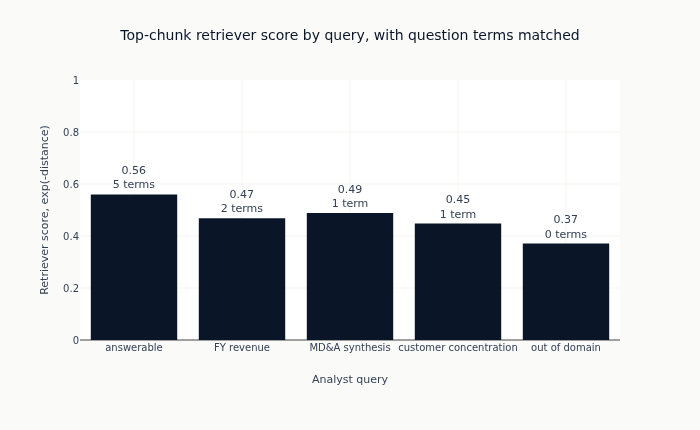

In [23]:
QUERY_LABELS = [
    "answerable",
    "FY revenue",
    "MD&A synthesis",
    "customer concentration",
    "out of domain",
]
labels = QUERY_LABELS[: len(retrieval_checks)] + [
    f"query {check['query']}" for check in retrieval_checks[len(QUERY_LABELS) :]
]
top_scores = [check["top_similarity"] or 0.0 for check in retrieval_checks]
term_counts = [len(check["matched_terms"]) for check in retrieval_checks]

fig = go.Figure(
    go.Bar(
        x=labels,
        y=top_scores,
        marker_color=COLORS["blue"],
        text=[
            f"{score:.2f}<br>{count} term{'' if count == 1 else 's'}"
            for score, count in zip(top_scores, term_counts, strict=True)
        ],
        textposition="outside",
    )
)
fig.update_layout(
    title="Top-chunk retriever score by query, with question terms matched",
    xaxis_title="Analyst query",
    yaxis_title="Retriever score, exp(-distance)",
    height=430,
    showlegend=False,
    margin=dict(t=80, b=90),
)
fig.update_yaxes(range=[0, 1])
show_plotly_with_alt(
    fig,
    "Five bars on a retriever-score axis running from zero to one. All five fall between "
    "roughly a third and a little over half the height of the axis, four of them below its "
    "midpoint and the tallest just above it. The answerable query is the tallest and its "
    "label reports the most matched terms; the three financial queries follow at similar "
    "heights with one or two matched terms each; the out-of-domain query is the shortest "
    "and matched none. The gap between the tallest and the shortest bar is smaller than "
    "the empty space above all of them.",
)

这些柱子大致落在坐标轴的三分之一到略高于二分之一之间，它们彼此之间的差异小于它们与坐标轴任一端的差异。正是这种压缩使得原始分数不能充当护栏：排序是对的，而“该语料库能回答你的问题”与“该语料库讲的是完全不同的东西”之间的距离，只占该数值所报告尺度的一小部分。

## 7. 数值工作流：检索 → 抽取 → 计算 → 叙述

数值问题正是 RAG 最常静默失败的地方：一个语言流畅的模型会欣然*说出*一个它从未真正计算过的计算数值。防护措施是将算术完全排除在语言模型之外——检索证据，将报告的数值**抽取**到类型化 schema 中，在 Python 中**计算**，并**叙述**结果，同时提供回溯到源 chunk 的引用轨迹。下面的代码块以确定性方式运行（不使用 LLM），因此抽取出的数字和计算出的聚合值可复现且可审计。

### 类型化 schema 与数值抽取器

`ExtractedFigure` 是每个检索到的美元金额被解析成的类型化 schema；正则表达式将 `$X billion/million/thousand` 归一化为 USD 浮点数，这样计算步骤就无需重新解析自由文本。

In [24]:
@dataclass
class ExtractedFigure:
    raw: str
    value_usd: float
    source: str


_MONEY_RE = re.compile(r"\$\s?([\d,]+(?:\.\d+)?)\s?(billion|million|thousand)?", re.IGNORECASE)
_SCALE = {"billion": 1e9, "million": 1e6, "thousand": 1e3, "": 1.0}

### 抽取步骤

遍历 `(text, source)` 对——无论是检索到的 chunk 还是财务报表摘录——将每个以 `$` 计价的数值提取到类型化 schema 中，并保留 source id，以便每个值仍然可引用。

In [25]:
def extract_dollar_figures(items) -> list[ExtractedFigure]:
    """Pull $-denominated figures from (text, source) pairs into a typed schema."""
    figures: list[ExtractedFigure] = []
    for text, source in items:
        for match in _MONEY_RE.finditer(text):
            amount = float(match.group(1).replace(",", ""))
            scale = _SCALE[(match.group(2) or "").lower()]
            figures.append(
                ExtractedFigure(raw=match.group(0), value_usd=amount * scale, source=source)
            )
    return figures

### 叙述型语料库包含什么

上文加载的语料库存储叙述性文本——业务描述和风险因素，围绕每份申报文件提及供应商之处截取——并且几乎不包含美元数值。财务报表表格位于单独的 exhibit 中，生产系统会为数值问题摄取该部分。

下面的检查比看起来更窄。针对该索引检索一个关于美元数值的问题，它仍会像往常一样返回其 `top_k` 个 chunk；统计这些 chunk 中以 `$` 计价的数值，结果一个也没有。

这确立了一件事：这些特定 chunk 不包含美元金额，因此抽取并计算步骤没有可处理的内容。它并不能确立该语料库无法回答前面那些问题——增长率和集中度份额可以只用百分比表述，附近没有任何美元金额——也完全没有说明本次查询未检索到的 chunk。可回答性是另一个问题，需要单独的证据。

它值得保留的原因在于它是可证伪的，而第 6 节的命中计数则不是。

In [26]:
NUMERIC_QUESTION = (
    "What are the largest reported dollar figures in the filing's financial discussion?"
)

numeric_retriever = index.as_retriever(similarity_top_k=TOP_K) if index is not None else None
if numeric_retriever is not None:
    narrative_nodes = numeric_retriever.retrieve(NUMERIC_QUESTION)
    narrative_figures = extract_dollar_figures(
        (n.text, n.metadata.get("accession_no", n.metadata.get("symbol", "?")))
        for n in narrative_nodes
    )
    print(f"Question: {NUMERIC_QUESTION}")
    print(
        f"Retrieved {len(narrative_nodes)} narrative chunks; "
        f"extracted {len(narrative_figures)} dollar figures."
    )
    if not narrative_figures:
        print("These chunks carry no dollar amounts, so there is nothing to extract from")
        print("them. Numeric questions need the financial-statement exhibit, below.")
    else:
        print(
            f"Found {len(narrative_figures)} figure(s) in these chunks; the "
            "financial-statement exhibit (below) remains the authoritative source."
        )
else:
    print("No index available - cannot run numeric workflow.")

Question: What are the largest reported dollar figures in the filing's financial discussion?
Retrieved 5 narrative chunks; extracted 0 dollar figures.
These chunks carry no dollar amounts, so there is nothing to extract from
them. Numeric questions need the financial-statement exhibit, below.


### 基于财务报表证据的检索 → 抽取 → 计算 → 叙述

下面受控的摘录代表 10-K 的财务报表部分（即叙述型语料库省略的部分）。它们包含分析师会查询的真实报告数值。机制才是要点：每个检索到的摘录都被解析到类型化的 `ExtractedFigure` schema 中，同比变化**在 Python 中计算**，并叙述结果，同时引用源摘录。它们检验的是算术溯源，而不是检索准确率。

In [27]:
# Controlled financial-statement fixtures for the arithmetic oracle.
FINANCIAL_EXCERPTS = [
    {"id": "fs_total_2023", "text": "Total net sales were $383.3 billion in fiscal 2023."},
    {"id": "fs_total_2022", "text": "Total net sales were $394.3 billion in fiscal 2022."},
    {"id": "fs_products_2023", "text": "Products net sales were $298.1 billion in fiscal 2023."},
    {"id": "fs_services_2023", "text": "Services net sales were $85.2 billion in fiscal 2023."},
]


figures = {
    f.source: f for f in extract_dollar_figures((e["text"], e["id"]) for e in FINANCIAL_EXCERPTS)
}

# Compute year-over-year total-net-sales growth in code.
total_2023 = figures["fs_total_2023"].value_usd
total_2022 = figures["fs_total_2022"].value_usd
yoy_growth = (total_2023 - total_2022) / total_2022

# Consistency check: products + services should reconcile to total net sales.
products_2023 = figures["fs_products_2023"].value_usd
services_2023 = figures["fs_services_2023"].value_usd
segment_sum = products_2023 + services_2023

print("Extract -> Compute trace (arithmetic done in Python, not by an LLM):")
for fid, fig in figures.items():
    print(f"  {fig.raw:>18}  = ${fig.value_usd:,.0f}   [source: {fid}]")
print(f"\n  YoY total net sales growth: {yoy_growth:.1%} (sources fs_total_2023, fs_total_2022)")
print(
    f"  Products + Services FY2023: ${segment_sum:,.0f} "
    f"vs reported total ${total_2023:,.0f} "
    f"(reconciles: {abs(segment_sum - total_2023) < 1e8})"
)
assert abs(segment_sum - total_2023) < 1e8
assert abs(yoy_growth - ((383.3 - 394.3) / 394.3)) < 1e-12

Extract -> Compute trace (arithmetic done in Python, not by an LLM):
      $383.3 billion  = $383,300,000,000   [source: fs_total_2023]
      $394.3 billion  = $394,300,000,000   [source: fs_total_2022]
      $298.1 billion  = $298,100,000,000   [source: fs_products_2023]
       $85.2 billion  = $85,200,000,000   [source: fs_services_2023]

  YoY total net sales growth: -2.8% (sources fs_total_2023, fs_total_2022)
  Products + Services FY2023: $383,300,000,000 vs reported total $383,300,000,000 (reconciles: True)


语言模型被排除在且仅排除在一个步骤之外：算术。它可以检索，可以抽取到类型化 schema 中，也可以叙述结果，但减法和除法在 Python 中对每个都带有 source id 的值执行。要求模型计算增长率时，无论它是否真的计算过，它都会给出一个看似合理的数字，而且再多的提示也无法让这一点变得可检查。将算术移出后，它在构造上就是可检查的——上方的对账断言要么成立，要么使 notebook 停止运行。

## 8. 总结

| 组件 | 实现 |
|-----------|---------------|
| **文档加载** | 规范 parquet 记录；排序后的平面文件回退 |
| **文档解析** | SentenceSplitter 句子窗口 |
| **分块** | SentenceSplitter（512 tokens，50 overlap） |
| **嵌入** | BGE-small-en（本地）；生产环境使用 voyage-finance-2 或 text-embedding-3 |
| **向量存储** | ChromaDB（每次运行独立重建） |
| **检索** | Top-k 相似度搜索 |
| **生成** | 默认仅检索；仅当 `RUN_LIVE_LLM=True` 时使用 GPT-4o-mini |
| **评估** | 轻量级评估框架诊断 |

评估这一行是表中最为薄弱的一行，下面的总结说明了原因：覆盖率不可能失败，而引用率和弃答率没有可评分的生成答案。本次运行真正能确认的是第 6 节中检索侧的结果：分数将五个问题按其标签所暗示的顺序排序，术语检查在其返回结果中未发现域外问题的任何内容。

In [28]:
print("=== 10-K RAG Assistant Summary ===\n")

print(f"Documents processed: {len(documents) if documents else 0}")
print(f"Queries executed: {len(query_results)}")
print(f"Successful queries: {sum(1 for r in query_results if r['status'] == 'success')}")
print(f"Retrieval top_k: {TOP_K}")

if ragas_metrics:
    print("\nHarness Metrics:")
    for metric, value in ragas_metrics.items():
        if value is None:
            print(f"  {metric}: n/a (LLM disabled)")
        elif isinstance(value, float):
            print(f"  {metric}: {value:.2%}")
        else:
            print(f"  {metric}: {value}")

=== 10-K RAG Assistant Summary ===

Documents processed: 20
Queries executed: 5
Successful queries: 5
Retrieval top_k: 5

Harness Metrics:
  retrieval_coverage: 100.00%
  citation_presence_rate: n/a (LLM disabled)
  abstention_rate: n/a (LLM disabled)
  n_queries: 5
  mode: retrieval_only


## 关键要点

1. **命中数不是检索指标。** `similarity_top_k` 没有相关性阈值，因此对索引能够接收的每个查询都返回 k 个 chunk，包括语料库未收录的公司和年份。因此本次运行中检索覆盖率显示为完整，甚至包括一个关于氦沸点的问题。任何失败情形为“索引未构建”的检查，检查的是数据摄入，而不是检索。

2. **相似度分数用于排序，不用于决策。** 五个最高分将问题正确排序，可回答问题得分最高，域外问题最低，说明嵌入在发挥作用。但这些分数落在狭窄区间内且不含零，关于氦的问题得分低于其他问题，而不是不存在。要把这种排序转化为接受或弃答决策，需要阈值，而阈值是语料库和模型的属性，必须用答案已知的问题来校准。校准才是工作所在；分数本身不是护栏。

3. **语料库决定哪些问题可提问，而确认这一点需要证据。** 这些是围绕供应商讨论截取的叙述性摘录，因此预期三个财务问题会失败——但预期并不等于测量。本次运行确认的范围更窄，值得单独区分：为涉及美元金额的问题检索到的 chunk 不含任何美元金额，因此提取步骤没有可处理内容。语料库是否在未检索到的某处包含以百分比表示的营收增长率，是另一个问题；回答它需要搜索该证据，而不是仅凭五个 chunk 中不存在来判断。

4. **把算术运算留在模型之外。** 检索、提取到类型化 schema、用 Python 计算、用来源 id 叙述。让模型计算时，无论对错都会给出看似合理的数字，而这种差异无法从答案中看出来。

5. **引用与弃答契约在此处只是陈述，并未实际执行。** `RUN_LIVE_LLM` 处于关闭状态，因此 `CITATION_PROMPT` 从未发送，两项比率都报告为不可用，而不是通过。[`04_ragas_evaluation`](04_ragas_evaluation.ipynb) 是这些检查器针对能触发它们的 fixtures 运行的地方。

**下一步**：[`06_esg_rag_vs_finetune`](06_esg_rag_vs_finetune.ipynb) 在 ESG 分析上将检索与微调分类器进行比较。